# Monte Carlo Simulation of JKJ3B Model for NiX2
### Purposes : 
simulate the JKJ3B model $$ $$ and track how spin-order, polarization evolves with temperature

### Step 1 : Import

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# print(Path.cwd())

from nix2_mc import LatticeNiX2, SpinModelNiX2, MonteCarloNiX2
from nix2_mc_output import create_run_folder, save_temperature_results

In [2]:
from nix2_model_builders import *

### Step 2 : Lattice

In [3]:
Lmuc = 7
Nmuc = 4
Na = Nmuc * Lmuc
Nb = 2 * Na
# Nb = 2
lattice_geometry = "rectangular"

nix2_lattice = build_nix2_lattice(Na, Nb, geometry=lattice_geometry)

### Step 3 : JKJ3B Model

a model from the PRL 2023

In [6]:
# ================================
# J1prime & Kitaev parameters
# for simulating proper screw order
# ================================
J1prime = -5
Kitaev = 0.3 * abs(J1prime)
J1mat = exchange_from_hk(J1prime, Kitaev)
J1iso = np.sum(np.diag(J1mat))/3
Azz = 0.03 * abs(J1prime) # 0.140

B_biquad = 0.15 * J1prime
J2iso = 0 # -0.155
J3iso = 0.375 * abs(J1prime) # J3iso should be positive !!!
J2mat = J2iso * np.eye(3)
J3mat = J3iso * np.eye(3)

# ================================
# J1 tensor
# ================================
# # exchange
# J1iso = -7.0  # meV
# Jxx = -1.0
# Jyy = 1.4
# Jzz = -0.3
# Jyz = -1.4
# J1mat = exchange_from_iso_aniso(J1iso, Jxx=Jxx, Jyy=Jyy, Jzz=Jzz, Jxy=0.0, Jxz=0.0, Jyz=Jyz)

# J2iso = 0.0   # meV
# J3iso = +5.8  # meV

# # single-ion anisotropy
# Azz = 0.6 * np.abs(J1iso)

# B_biquad = 0.0

# ================================
# set up model parameters
# ================================
model_params = {
    "J1": J1mat,
    "J2": J2iso,
    "J3": J3iso,
    "Azz": Azz,
    "B_biquad": B_biquad,
    "zeeman": (0.0, 0.0, 0.0)
}

# build model
nix2_model = build_nix2_model(J1mat, J3=J3iso, J2iso=J2iso, 
                              Azz=Azz, B_biquad=B_biquad, B_field=(0.0, 0.0, 0.0), 
                              geometry=lattice_geometry)

In [7]:
print("ratio of J3 to J1iso : ", J3iso / J1iso)
print("ratio of B to J1iso : ", B_biquad / J1iso)

ratio of J3 to J1iso :  -0.4166666666666667
ratio of B to J1iso :  0.16666666666666666


### Step 4 : add M tensor for polarization calculation

In [8]:
# M is in units of 10^-5 e Angstrom; the resulting P is dipole per Ni.
M01 = np.array([[20, 0, 32], [0, 348, -520], [0, 25, 0]], dtype=float)

prepare_M_tensors(nix2_model, lat=nix2_lattice, M01=M01, lat_geom=lattice_geometry)

In [9]:
import secrets

seed = secrets.randbits(128)
current_rng = np.random.default_rng(seed=seed)
nix2_mc = MonteCarloNiX2(lattice=nix2_lattice, spin_model=nix2_model, seed=seed)

Building M tensor arrays for electric polarization.


In [10]:
# Plotting helpers and common appearance.
from plotting_3d_spins import (
    PLOT_CONFIG, plot_spin_config, plot_spin_texture, plot_spin_angles, plot_curves,
)
plt.rcParams.update(PLOT_CONFIG)

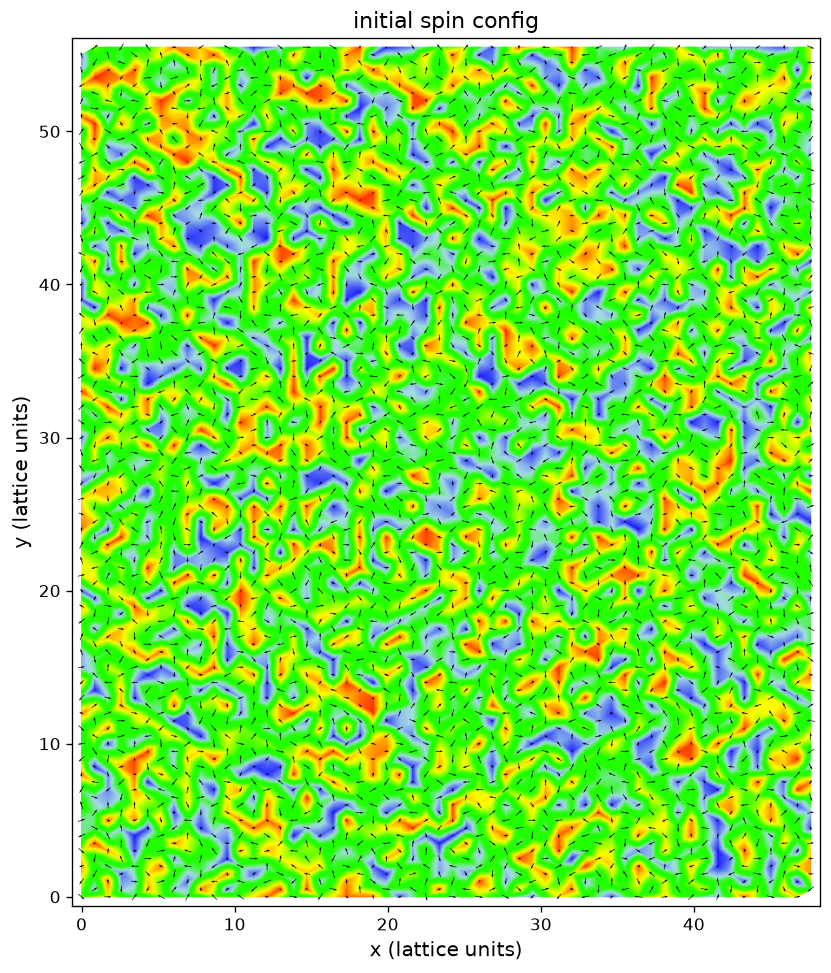

In [11]:
# Current spin configuration: Sz background and in-plane spin arrows.
ax = plot_spin_texture(
    nix2_mc.spin_config, nix2_mc.lat,
    title="initial spin config", figsize=(8,8),colorbar=False
)
plt.show()

### temperatures from HIGH to LOW for annealing
I have checked the validity of this annealing in another notebook

In [12]:
from nix2_mc_protocols import *

In [14]:
TK_init_list = [69, 50, 19]
TK_final_list = [51, 19, 1]
cooling_method_list = ["linear", "linear", "linear"]
cooling_rate_list = [10, 32, 10]

TK_list = set_temperature_schedule(
    TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
)

In [13]:
# measurements = make_measurements(
#     nix2_mc,
#     observables=["energy", "magnetization"],
# )

In [ ]:
num_eq_sweeps = 20000
converg_per_every = 20
num_meas_sweeps = 20000
meas_per_every = 5

In [18]:
mc_parameters={
    # lattice parameters
    "Nx": Na,
    "Ny": Nb,
    "Ns": nix2_lattice.Ns,
    "geometry": lattice_geometry,
    
    # model parameters
    "model_params": model_params,

    # Monte Carlo parameters
    "seed": seed,
    "num_eq_sweeps": num_eq_sweeps, 
    "converg_per_every": converg_per_every,
    "num_meas_sweeps": num_meas_sweeps, 
    "meas_per_every": meas_per_every,
    "temperatures_info":(TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list),
    "reset_probability": 0.02,
}

current_folder = create_run_folder(root="nix2_simulation_results", parameters=mc_parameters,
                                    prefix="NiX2_JKJ3B_proper_screw_order_")

### MC Simulation Starts

In [19]:
from nix2_mc_protocols import run_mc_annealing

results = run_mc_annealing(
    nix2_mc, TK_list, current_folder,
    num_eq_sweeps=num_eq_sweeps,
    num_meas_sweeps=num_meas_sweeps,
    converg_per_every=converg_per_every,
    meas_per_every=meas_per_every,
    observables=["E", "P", "Cv"],
)

T = 69.00 K, energy = -14946.628397, electric_polarization = [-0.088636  0.309775 -0.013835], heat_capacity = 0.54663
T = 67.00 K, energy = -15246.957362, electric_polarization = [0.071851 0.204957 0.026969], heat_capacity = 0.592565
T = 65.00 K, energy = -15587.127286, electric_polarization = [-0.437047  0.051462 -0.042546], heat_capacity = 0.639614
T = 63.00 K, energy = -15918.045507, electric_polarization = [-1.006409  0.567084  0.047755], heat_capacity = 0.639455
T = 61.00 K, energy = -16261.150065, electric_polarization = [ 0.453659  0.074387 -0.011204], heat_capacity = 0.653922
T = 59.00 K, energy = -16623.793122, electric_polarization = [ 0.083942  0.773652 -0.007292], heat_capacity = 0.662972
T = 57.00 K, energy = -16994.465234, electric_polarization = [ 0.030991 -0.868862  0.006106], heat_capacity = 0.708929
T = 55.00 K, energy = -17384.208746, electric_polarization = [ 0.212715 -0.215893 -0.011893], heat_capacity = 0.686828
T = 53.00 K, energy = -17793.655148, electric_polari

### Step 7 : Plotting final spin configuration

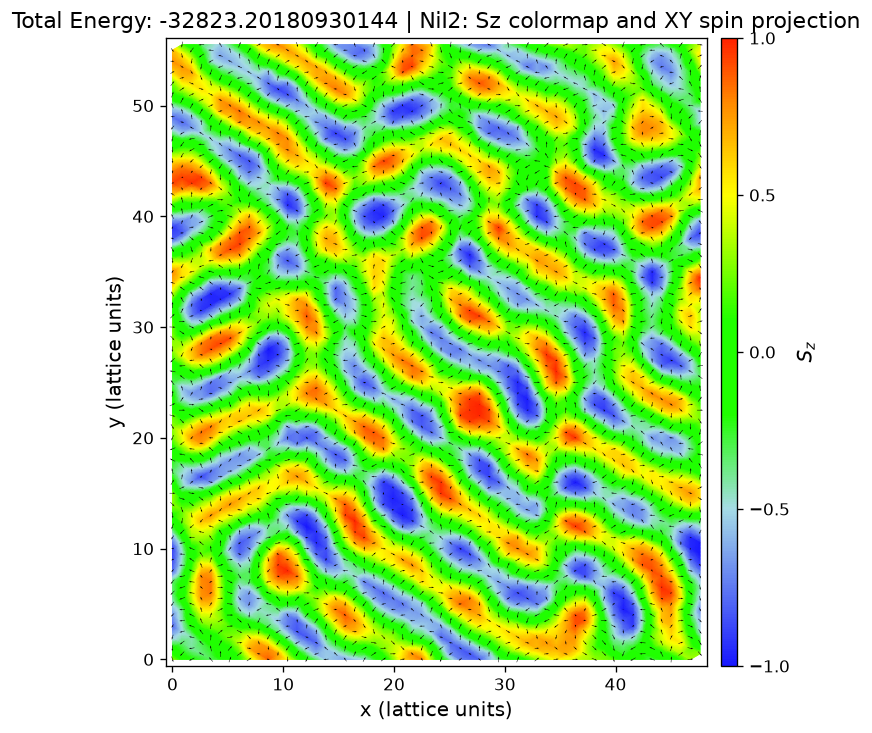

In [21]:
total_energy = nix2_mc.total_energy()

ax = plot_spin_texture(
    spins=nix2_mc.spin_config,
    lattice=nix2_mc.lat,
    title=f"Total Energy: {total_energy} | NiI2: Sz colormap and XY spin projection",
    figsize=(8, 6),
    arrow_scale=1.8,
    arrow_width=0.045,
)
plt.show()

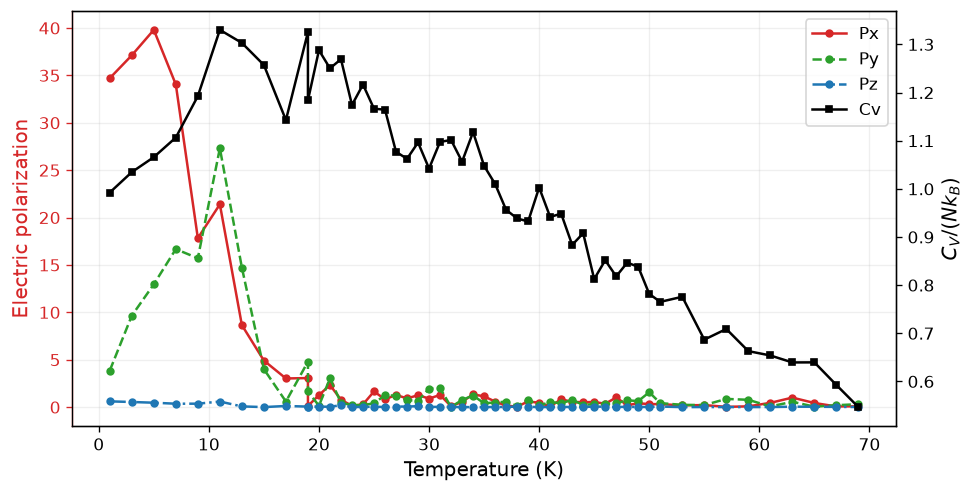

In [22]:
fig, ax1, ax2 = plot_curves(
    results["temperatures_K_list"], np.abs(results["P_data"]).T, results["Cv_data"],
    xlabel="Temperature (K)",
    ylabel1="Electric polarization", ylabel2=r"$C_V/(N k_B)$",
    label1=["Px", "Py", "Pz"], label2="Cv",
    colors=(["tab:red", "tab:green", "tab:blue"], "black"),
    flag_show=True,
)

(28, 56, 3)


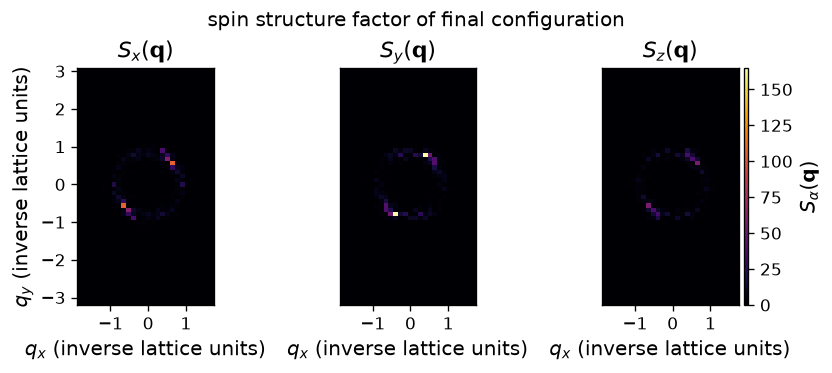

In [56]:
# Structure factor of the final configuration (after LLG when run in order).
%matplotlib inline
from plotting_3d_spins import plot_Sq

q1, q2, S_q = nix2_mc.spin_structure_factor(component_resolved=True)
print(S_q.shape)
h, k = np.meshgrid(np.fft.fftshift(q1) / nix2_mc.lat.Nx,
                   np.fft.fftshift(q2) / nix2_mc.lat.Ny, indexing="ij")
b1, b2 = 2 * np.pi * np.linalg.inv(nix2_mc.lat.a_vecs).T
qx, qy = h * b1[0] + k * b2[0], h * b1[1] + k * b2[1]
S_q = np.fft.fftshift(S_q, axes=(0, 1))

fig, axes = plot_Sq(qx, qy, S_q, figsize=(7,3), title="spin structure factor of final configuration")  # XYZ maps; use S_q.sum(axis=-1) for total intensity.


In [48]:
# Largest sampled intensities in each component; columns: qx, qy, intensity.
n_peaks = 6
Sq_peaks = {}
for component, name in enumerate(("Sx", "Sy", "Sz")):
    intensity = S_q[..., component].ravel()
    indices = np.argsort(-intensity, kind="stable")[:n_peaks]
    Sq_peaks[name] = np.column_stack((qx.ravel()[indices], qy.ravel()[indices], intensity[indices]))
    print(f"\n{name}: {'qx':>12} {'qy':>12} {'intensity':>14}")
    for qxi, qyi, value in Sq_peaks[name]:
        print(f"    {qxi:12.6f} {qyi:12.6f} {value:14.6g}")



Sx:           qx           qy      intensity
        0.647785     0.560999         76.994
       -0.647785    -0.560999         76.994
       -0.518228    -0.673198        60.4496
        0.518228     0.673198        60.4496
       -0.388671    -0.897598        38.1393
        0.388671     0.897598        38.1393

Sy:           qx           qy      intensity
       -0.388671    -0.785398        149.523
        0.388671     0.785398        149.523
       -0.518228    -0.785398        47.9113
        0.518228     0.785398        47.9113
        0.647785     0.560999        40.1938
       -0.647785    -0.560999        40.1938

Sz:           qx           qy      intensity
       -0.518228    -0.673198        40.7644
        0.518228     0.673198        40.7644
       -0.388671    -0.785398        40.4889
        0.388671     0.785398        40.4889
       -0.647785    -0.560999        32.2204
        0.647785     0.560999        32.2204


### Spiral period from the structure-factor peaks

For a spin spiral with phase
$$
\phi(\mathbf r)=\mathbf q\cdot\mathbf r+\phi_0,
$$
one full rotation along the propagation direction requires
$$
|\mathbf q|\lambda=2\pi.
$$

Thus, for Cartesian peak coordinates $(q_x,q_y)$,
$$
\boxed{\lambda=\frac{2\pi}{\sqrt{q_x^2+q_y^2}}}.
$$

With $q_x,q_y$ expressed in units of $a^{-1}$:

| $q_x$ | $q_y$ | $\lambda/a$ |
|---:|---:|---:|
| 0.647785 | 0.560999 | 7.33 |
| 0.518228 | 0.673198 | 7.40 |
| 0.388671 | 0.785398 | 7.17 |
| 0.388671 | 0.897598 | 6.42 |

The peaks at $\mathbf q$ and $-\mathbf q$ give the same period. And the period $\lambda/a$ is similar to what mentioned in the paper, approximately 7 unit cell.

From the spin configuration figure, we can find that in some domains, the spin order along the bond directions are similar.

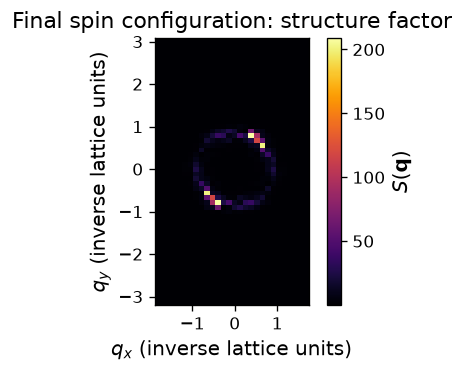

In [57]:
# Structure factor of the current final spin configuration.
q1, q2, S_q_mag = nix2_mc.spin_structure_factor(component_resolved=False)
h, k = np.meshgrid(np.fft.fftshift(q1) / nix2_mc.lat.Nx,
                   np.fft.fftshift(q2) / nix2_mc.lat.Ny, indexing="ij")
b1, b2 = 2 * np.pi * np.linalg.inv(nix2_mc.lat.a_vecs).T
qx, qy = h * b1[0] + k * b2[0], h * b1[1] + k * b2[1]

fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
image = ax.pcolormesh(qx, qy, np.fft.fftshift(S_q_mag), shading="auto", cmap="inferno")
fig.colorbar(image, ax=ax, label=r"$S(\mathbf{q})$")
ax.set(xlabel=r"$q_x$ (inverse lattice units)",
       ylabel=r"$q_y$ (inverse lattice units)", aspect="equal",
       title="Final spin configuration: structure factor")
plt.show()

### Step 8 : LLG relaxation to reach the local minimum

In [51]:
from nix2_llg import get_torques, LLG_relaxation, relax_spins

In [54]:
alpha = 0.5
t_end = 100.0  # ps
energy_before_llg = nix2_mc.total_energy()
# relax spins using LLG
spins_llg = relax_spins(nix2_mc.spin_config, nix2_mc.ham,
                        alpha=alpha, t_end=t_end)

# update the spin configuration
nix2_mc.spin_config = spins_llg.copy()

# compute total energy and maximum torque after relaxation
total_energy = nix2_mc.total_energy()
max_rate = np.max(np.linalg.norm(
    get_torques(alpha, spins_llg, nix2_ham=nix2_mc.ham), axis=-1))
print(f"Energy: {energy_before_llg:.6f} -> {total_energy:.6f} meV")
print(f"Max |dS/dt| = {max_rate:.3e} ps^-1")

Energy: -33088.003161 -> -33090.650647 meV
Max |dS/dt| = 1.928e-03 ps^-1


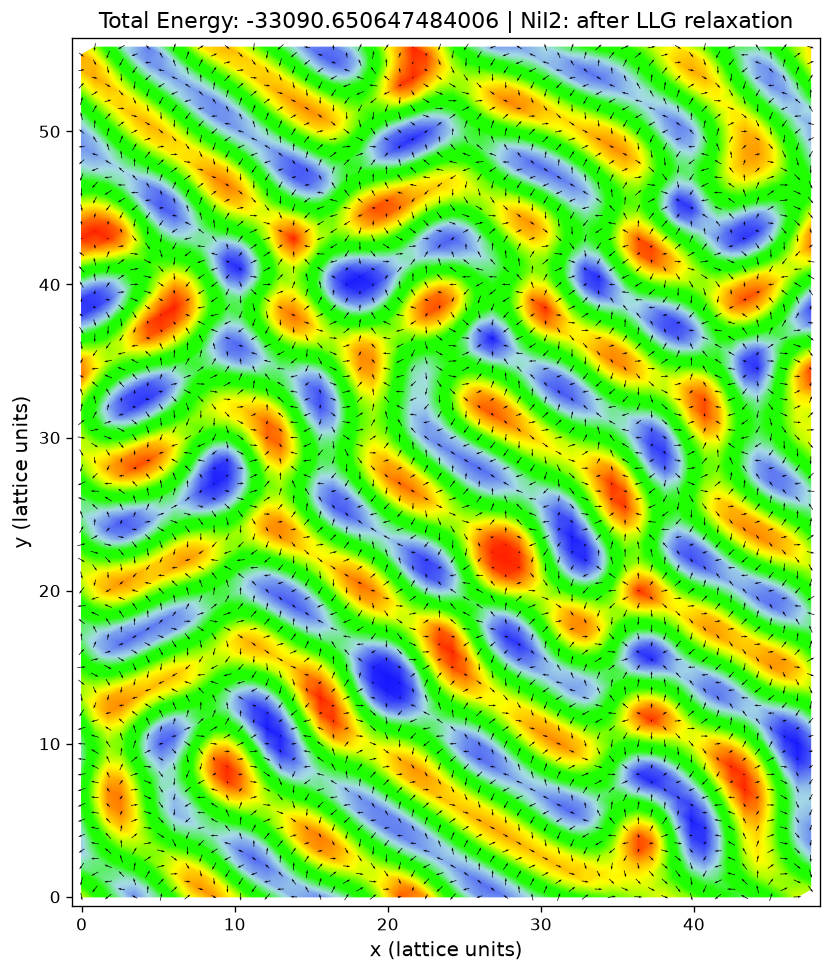

In [55]:
total_energy = nix2_mc.total_energy()

ax = plot_spin_texture(
    spins=spins_llg,
    lattice=nix2_mc.lat,
    title=f"Total Energy: {total_energy} | NiI2: after LLG relaxation",
    figsize=(8, 8),
    arrow_scale=1.8,
    arrow_width=0.045,
    colorbar=False
)
plt.show()